In [1]:
	# Load data
import pandas as pd
data = pd.read_csv('..\data\jakarta_house_imputed.csv')
data.head()

,index,price,district,city,bed_rooms,bath_rooms,carport,land_area,building_area
0,1,5900000000,Citra Garden,Jakarta Barat,2,4,2,250.0,350.0
1,2,2700000000,Jelambar,Jakarta Barat,4,2,0,100.0,225.0
2,3,2200000000,Jelambar,Jakarta Barat,3,3,0,60.0,140.0
3,4,1900000000,Jelambar,Jakarta Barat,3,2,0,60.0,120.0
4,5,2100000000,Tanjung Duren,Jakarta Barat,4,3,0,56.0,108.0


In [2]:
data.info()
data.describe()
data['city'].value_counts()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   index          10000 non-null  int64  
 1   price          10000 non-null  int64  
 2   district       10000 non-null  str    
 3   city           10000 non-null  str    
 4   bed_rooms      10000 non-null  int64  
 5   bath_rooms     10000 non-null  int64  
 6   carport        10000 non-null  int64  
 7   land_area      9997 non-null   float64
 8   building_area  9995 non-null   float64
dtypes: float64(2), int64(5), str(2)
memory usage: 937.6 KB


city
Jakarta Selatan    3379
Jakarta Barat      2622
Jakarta Utara      1739
Jakarta Timur      1690
Jakarta Pusat       570
Name: count, dtype: int64

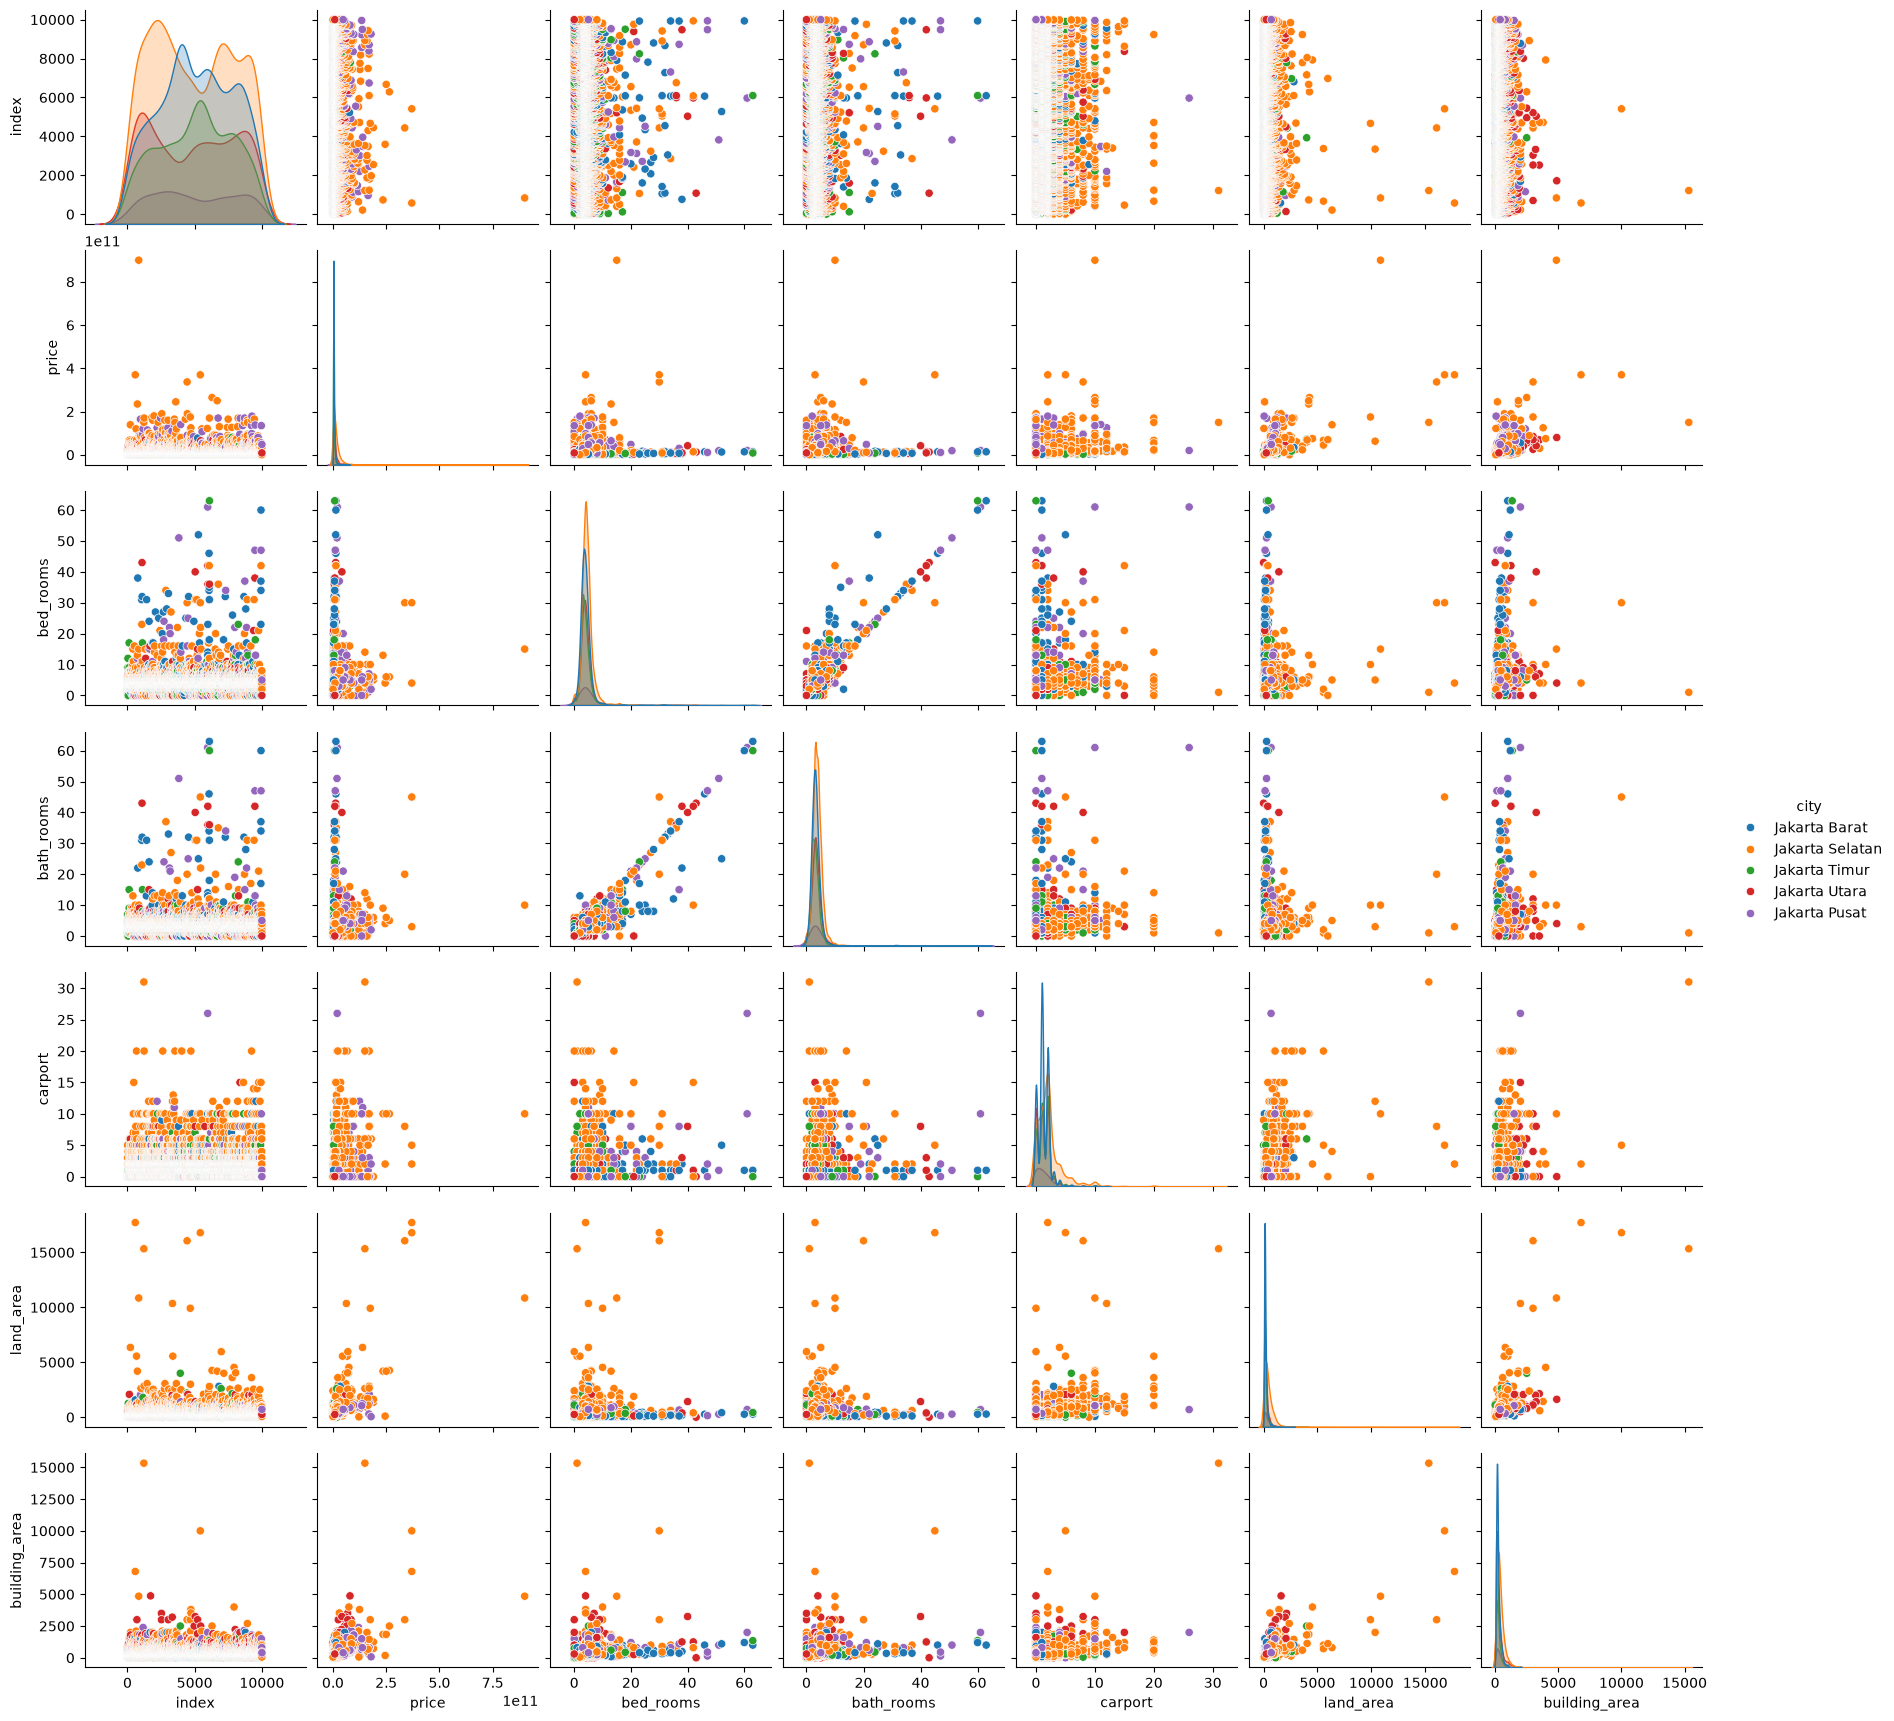

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt
	
sns.pairplot(data, hue='city')
plt.show()

In [9]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Load data CSV lu (misal nama file-nya 'data_rumah.csv')
df = pd.read_csv('../data/jakarta_house_imputed.csv')

# Tentukan Target (y) dan Fitur (X)
# Ambil kolom angka saja (buang index, district, city)
X = df[['bed_rooms', 'bath_rooms', 'carport', 'land_area', 'building_area']]
y = df['price']

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Sekarang StandardScaler dijamin aman karena isinya angka semua!
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [13]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split

# 1. Bersihin dulu nilai kosong (NaN) di dataframe SEBELUM di-split
df = df.fillna(df.mean(numeric_only=True))

# 2. Tentukan fitur (X) dan target (y)
# (Pastikan kolom teks udah di-drop atau di-encode ya, kayak yang dibahas sebelumnya!)
X = df[['bed_rooms', 'bath_rooms', 'carport', 'land_area', 'building_area']] # contoh kolom angka
y = df['price']

# 3. Baru split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 4. Inisialisasi dan latih model KNN
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)
print("Model berhasil dilatih tanpa error! Mantap!")

Model berhasil dilatih tanpa error! Mantap!


In [14]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
	
y_pred = knn.predict(X_test)
print("Akurasi:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Laporan Klasifikasi:\n", classification_report(y_test, y_pred))

Akurasi: 0.11733333333333333
Confusion Matrix:
 [[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]
Laporan Klasifikasi:
               precision    recall  f1-score   support

     2200000       0.00      0.00      0.00         1
     2300000       0.00      0.00      0.00         0
     3800000       0.00      0.00      0.00         0
     4900000       0.00      0.00      0.00         1
     6850000       0.00      0.00      0.00         1
     7100000       0.00      0.00      0.00         0
    22000000       0.00      0.00      0.00         1
   116000000       0.00      0.00      0.00         0
   203000000       0.00      0.00      0.00         1
   230000000       0.00      0.00      0.00         0
   258000000       0.00      0.00      0.00         0
   281000000       0.00      0.00      0.00         1
   315000000       0.00      0.00      0.00         0
   330000000       0.00      0.00      0.00         0

d:\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: 

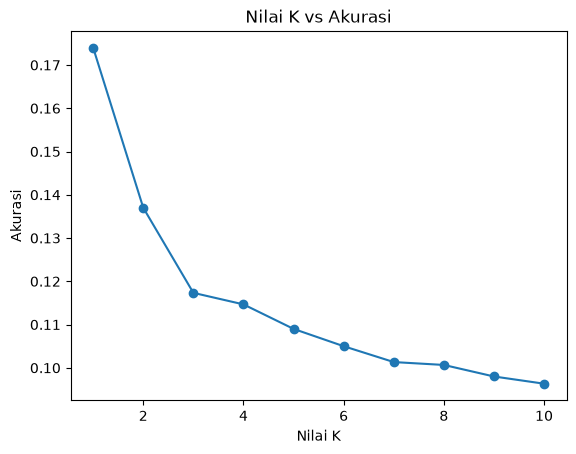

In [15]:
acc = []
for k in range(1, 11):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    acc.append(model.score(X_test, y_test))
	
plt.plot(range(1, 11), acc, marker='o')
plt.title('Nilai K vs Akurasi')
plt.xlabel('Nilai K')
plt.ylabel('Akurasi')
plt.show()
	